Member 1/3  (lr=0.001, n=166)
Member 2/3  (lr=0.0005, n=166)
Member 3/3  (lr=0.002, n=166)

Ensemble Accuracy: 46.0%


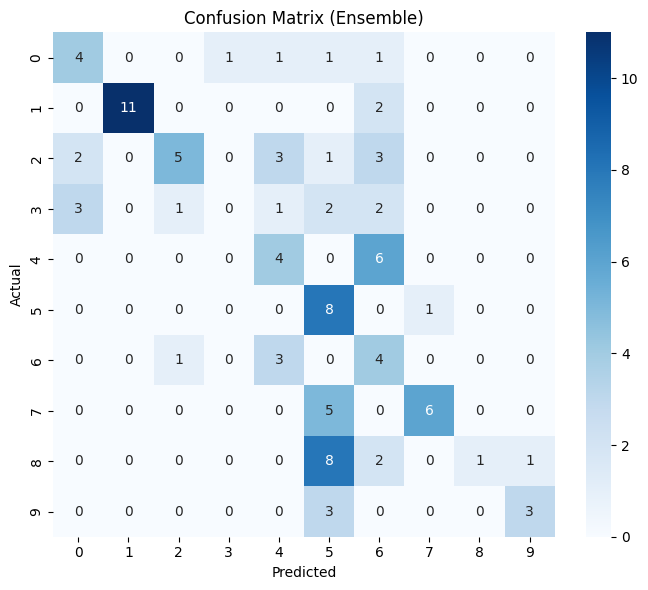

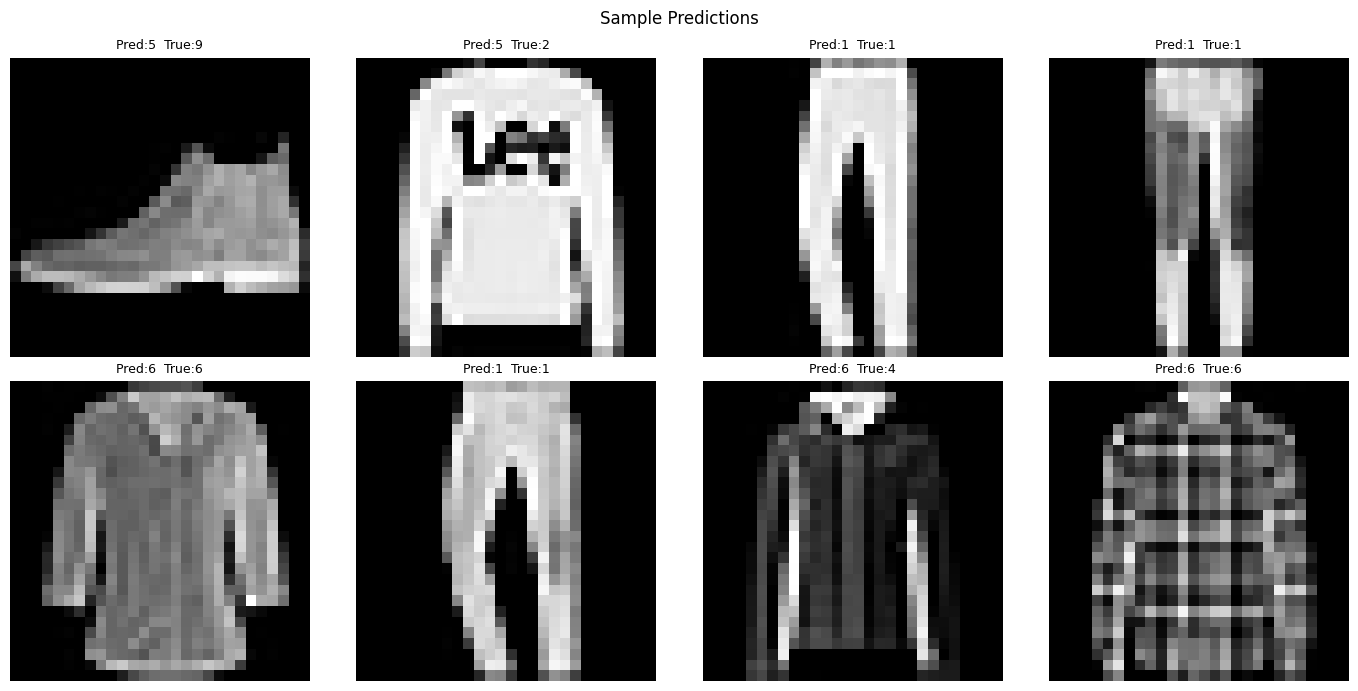

Done → confusion_matrix.png, samples.png


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torchvision.models import resnet18
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_MEMBERS = 3
NUM_CLASSES = 10
TRAIN_SIZE = 500
TEST_SIZE = 100

# --- Data (Fashion-MNIST: converted to 3-channel for ResNet) ---
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize([0.2866, 0.2866, 0.2866], [0.3539, 0.3539, 0.3539]),
])
full_train = datasets.FashionMNIST("./data", train=True, download=True, transform=transform)
full_test  = datasets.FashionMNIST("./data", train=False, download=True, transform=transform)

test_ds = Subset(full_test, range(TEST_SIZE))
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False)

# --- Model factory (ResNet18: 11M params vs ResNet50's 25M) ---
def make_model():
    m = resnet18(weights="IMAGENET1K_V1")
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, NUM_CLASSES))
    return m.to(device)

# --- Fine-tune with diversity ---
def fine_tune(model, train_loader, epochs, lr):
    for p in model.parameters():
        p.requires_grad = False
    for p in model.fc.parameters():
        p.requires_grad = True
    opt = optim.Adam(model.fc.parameters(), lr=lr)
    model.train()
    for _ in range(epochs):
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            nn.CrossEntropyLoss()(model(x), y).backward()
            opt.step()
    model.eval()

# --- Train ensemble members ---
models = []
indices = np.random.permutation(TRAIN_SIZE)
chunk = TRAIN_SIZE // NUM_MEMBERS
lrs = [1e-3, 5e-4, 2e-3]

for i in range(NUM_MEMBERS):
    subset_idx = indices[i * chunk : (i + 1) * chunk]
    member_ds = Subset(full_train, subset_idx)
    member_loader = DataLoader(member_ds, batch_size=32, shuffle=True)

    print(f"Member {i+1}/{NUM_MEMBERS}  (lr={lrs[i]}, n={len(subset_idx)})")
    m = make_model()
    fine_tune(m, member_loader, epochs=3, lr=lrs[i])
    models.append(m)

# --- Ensemble predict ---
def ensemble_predict(x):
    x = x.to(device)
    return torch.stack([m(x) for m in models]).mean(dim=0)

# --- Collect predictions ---
all_preds, all_labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        y = y.to(device)
        preds = ensemble_predict(x).argmax(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

acc = np.mean(np.array(all_preds) == np.array(all_labels))
print(f"\nEnsemble Accuracy: {acc*100:.1f}%")

# --- Confusion Matrix ---
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(all_labels, all_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Confusion Matrix (Ensemble)")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=100, bbox_inches="tight")
plt.show()

# --- Sample predictions ---
fig2, axes2 = plt.subplots(2, 4, figsize=(14, 7))
for i in range(8):
    img = transforms.ToPILImage()(full_test.data[i])
    axes2[i // 4, i % 4].imshow(img, cmap="gray")
    axes2[i // 4, i % 4].set_title(f"Pred:{all_preds[i]}  True:{all_labels[i]}", fontsize=9)
    axes2[i // 4, i % 4].axis("off")
fig2.suptitle("Sample Predictions", fontsize=12)
plt.tight_layout()
plt.savefig("samples.png", dpi=100, bbox_inches="tight")
plt.show()

print("Done → confusion_matrix.png, samples.png")